# Bank Marketing — Term Deposit Prediction

Predicting whether a bank customer will subscribe to a **term deposit** based on a direct marketing
campaign, using a **Decision Tree Classifier**, with a full workflow covering exploratory data analysis,
hyperparameter tuning, threshold analysis, and feature importance (both impurity-based and permutation-based).

**Dataset:** Bank Marketing Data Set (direct marketing campaigns of a Portuguese banking institution)


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
os.makedirs("visuals", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries imported and output folders ready!")

Libraries imported and output folders ready!


## 2. Load Dataset

In [2]:
df = pd.read_csv("bank.csv")
print(df.head())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  


## 3. Data Overview

In [3]:
df.shape

(11162, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [5]:
print("Columns : ")
for i, col in enumerate(df.columns, start=1):
    print(f"{i} . {col}")

Columns : 
1 . age
2 . job
3 . marital
4 . education
5 . default
6 . balance
7 . housing
8 . loan
9 . contact
10 . day
11 . month
12 . duration
13 . campaign
14 . pdays
15 . previous
16 . poutcome
17 . deposit


## 4. Data Cleaning

In [6]:
missing_sum = df.isnull().sum()
missing_percent = (missing_sum / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_sum,
    "Percentage (%)": missing_percent
}).round(2)

missing_data = missing_data.sort_values(by="Missing Values", ascending=False)
missing_data

,Missing Values,Percentage (%)
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 5. Target and Feature Overview

In [8]:
print("Target distribution:")
print(df["deposit"].value_counts())

print("\nTarget percentage:")
print(df["deposit"].value_counts(normalize=True) * 100)

Target distribution:
deposit
no     5873
yes    5289
Name: count, dtype: int64

Target percentage:
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


In [9]:
print("Numerical summary:")
print(df.describe())

Numerical summary:
                age       balance           day      duration      campaign  \
count  11162.000000  11162.000000  11162.000000  11162.000000  11162.000000   
mean      41.231948   1528.538524     15.658036    371.993818      2.508421   
std       11.913369   3225.413326      8.420740    347.128386      2.722077   
min       18.000000  -6847.000000      1.000000      2.000000      1.000000   
25%       32.000000    122.000000      8.000000    138.000000      1.000000   
50%       39.000000    550.000000     15.000000    255.000000      2.000000   
75%       49.000000   1708.000000     22.000000    496.000000      3.000000   
max       95.000000  81204.000000     31.000000   3881.000000     63.000000   

              pdays      previous  
count  11162.000000  11162.000000  
mean      51.330407      0.832557  
std      108.758282      2.292007  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       20.7500

In [10]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


job:
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64

marital:
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

education:
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64

default:
default
no     10994
yes      168
Name: count, dtype: int64

housing:
housing
no     5881
yes    5281
Name: count, dtype: int64

loan:
loan
no     9702
yes    1460
Name: count, dtype: int64

contact:
contact
cellular     8042
unknown      2346
telephone     774
Name: count, dtype: int64

month:
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943
apr     923
feb     776
oct     392
jan     344
sep     319
mar     276
dec     110
Name: count, dtype: int64

po

In [11]:
for col in df.columns:
    print(f"{col:12} -> {df[col].unique()[:10]}")

age          -> [59 56 41 55 54 42 60 37 28 38]
job          -> ['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown']
marital      -> ['married' 'single' 'divorced']
education    -> ['secondary' 'tertiary' 'primary' 'unknown']
default      -> ['no' 'yes']
balance      -> [2343   45 1270 2476  184    0  830  545    1 5090]
housing      -> ['yes' 'no']
loan         -> ['no' 'yes']
contact      -> ['unknown' 'cellular' 'telephone']
day          -> [ 5  6  7  8  9 12 13 14 15 16]
month        -> ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar']
duration     -> [1042 1467 1389  579  673  562 1201 1030  608 1297]
campaign     -> [ 1  2  3  4  6  5  8 11  9 10]
pdays        -> [ -1 166  91 147 170 150 171 126 182 110]
previous     -> [ 0  1  4  2  3 10  7  9  5 29]
poutcome     -> ['unknown' 'other' 'failure' 'success']
deposit      -> ['yes' 'no']


In [12]:
df["pdays"].describe()

count    11162.000000
mean        51.330407
std        108.758282
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         20.750000
max        854.000000
Name: pdays, dtype: float64

In [13]:
cols_to_check = ["education", "job", "contact", "poutcome"]
unknown_summary = {}

for col in cols_to_check:
    unknown_summary[col] = (df[col] == "unknown").sum()

print("Unknown counts per column:")
unknown_summary

Unknown counts per column:


{'education': np.int64(497),
 'job': np.int64(70),
 'contact': np.int64(2346),
 'poutcome': np.int64(8326)}

## 6. Exploratory Data Analysis (EDA)

### 6.1 Deposit Rate by Job

In [14]:
job_deposit = pd.crosstab(df["job"], df["deposit"], normalize="index") * 100
print(job_deposit.round(2))

deposit           no    yes
job                        
admin.         52.70  47.30
blue-collar    63.58  36.42
entrepreneur   62.50  37.50
housemaid      60.22  39.78
management     49.30  50.70
retired        33.68  66.32
self-employed  53.83  46.17
services       60.02  39.98
student        25.28  74.72
technician     53.92  46.08
unemployed     43.42  56.58
unknown        51.43  48.57


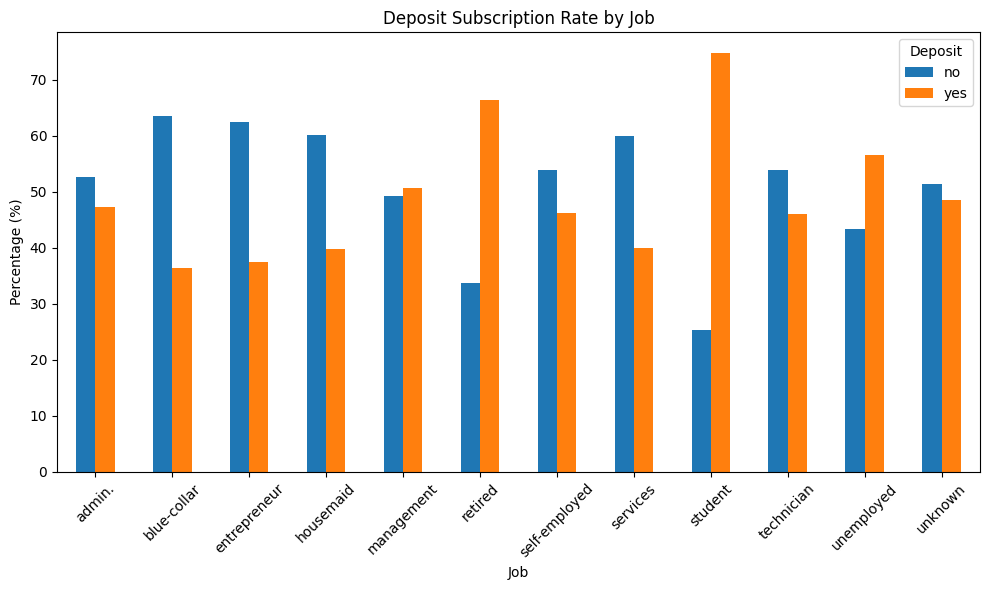

In [15]:
job_deposit.plot(kind="bar", figsize=(10, 6))
plt.title("Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Deposit")
plt.tight_layout()
plt.savefig("visuals/deposit_rate_by_job.png", dpi=150)
plt.show()

### 6.2 Deposit Rate by Education

In [16]:
def target_rate_by_category(df, feature, target="deposit"):
    result = pd.crosstab(df[feature], df[target], normalize="index") * 100
    return result.round(2)

target_rate_by_category(df, "education")

deposit,no,yes
education,,
primary,60.60,39.40
secondary,55.26,44.74
tertiary,45.89,54.11
unknown,49.30,50.70


### 6.3 Balance vs Deposit

In [17]:
df.groupby("deposit")["balance"].describe()

,count,mean,std,min,25%,50%,75%,max
deposit,,,,,,,,
no,5873.0,1280.227141,2933.411934,-6847.0,64.0,414.0,1324.0,66653.0
yes,5289.0,1804.267915,3501.104777,-3058.0,210.0,733.0,2159.0,81204.0


<Figure size 800x500 with 0 Axes>

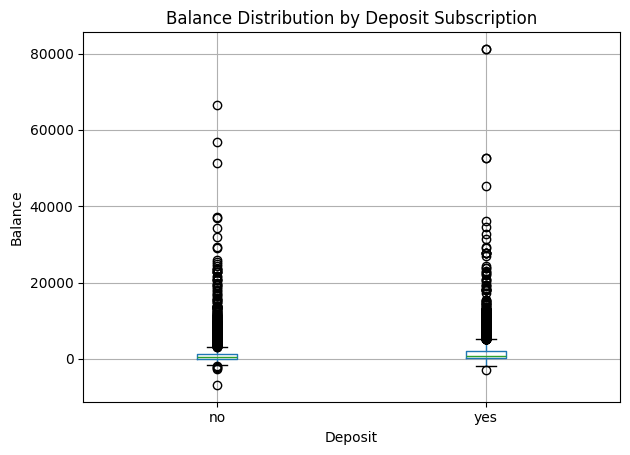

In [18]:
plt.figure(figsize=(8, 5))
df.boxplot(column="balance", by="deposit")
plt.title("Balance Distribution by Deposit Subscription")
plt.suptitle("")
plt.xlabel("Deposit")
plt.ylabel("Balance")
plt.tight_layout()
plt.savefig("visuals/balance_vs_deposit.png", dpi=150)
plt.show()

### 6.4 Age vs Deposit

In [19]:
df.groupby("deposit")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
deposit,,,,,,,,
no,5873.0,40.837391,10.264815,18.0,33.0,39.0,48.0,89.0
yes,5289.0,41.670070,13.497781,18.0,31.0,38.0,50.0,95.0


### 6.5 Deposit Rate by Previous Campaign Outcome

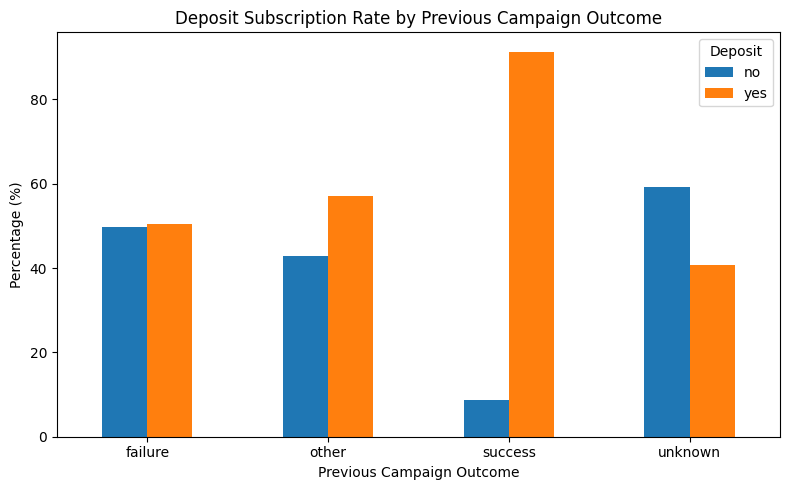

In [20]:
poutcome_deposit = target_rate_by_category(df, "poutcome")

poutcome_deposit.plot(kind="bar", figsize=(8, 5))
plt.title("Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Deposit")
plt.tight_layout()
plt.savefig("visuals/deposit_rate_by_poutcome.png", dpi=150)
plt.show()

### 6.6 Deposit Rate by Housing Loan, Personal Loan, and Contact Type

In [21]:
for feature in ["housing", "loan", "contact"]:
    print(f"\n{feature.upper()}")
    print(target_rate_by_category(df, feature))


HOUSING
deposit     no    yes
housing              
no       42.97  57.03
yes      63.36  36.64

LOAN
deposit     no    yes
loan                 
no       50.47  49.53
yes      66.85  33.15

CONTACT
deposit       no    yes
contact                
cellular   45.67  54.33
telephone  49.61  50.39
unknown    77.41  22.59


### 6.7 Campaign Contacts vs Deposit

In [22]:
for feature in ["campaign", "previous"]:
    print(f"\n{feature.upper()}")
    print(df.groupby("deposit")[feature].describe())


CAMPAIGN
          count      mean       std  min  25%  50%  75%   max
deposit                                                      
no       5873.0  2.839264  3.244474  1.0  1.0  2.0  3.0  63.0
yes      5289.0  2.141047  1.921826  1.0  1.0  2.0  3.0  32.0

PREVIOUS
          count      mean       std  min  25%  50%  75%   max
deposit                                                      
no       5873.0  0.528350  1.979610  0.0  0.0  0.0  0.0  41.0
yes      5289.0  1.170354  2.553272  0.0  0.0  0.0  1.0  58.0


<Figure size 800x500 with 0 Axes>

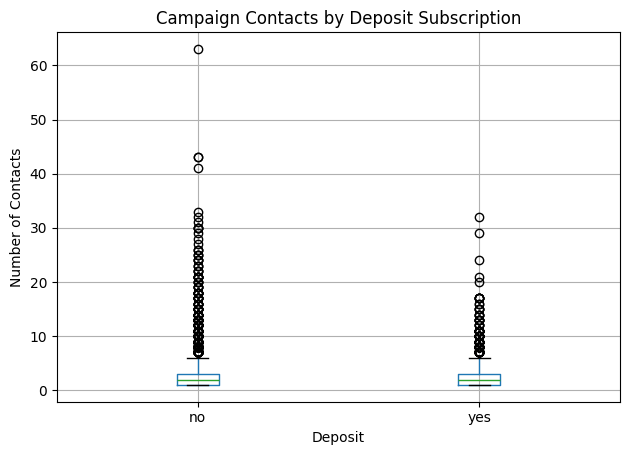

In [23]:
plt.figure(figsize=(8, 5))
df.boxplot(column="campaign", by="deposit")
plt.title("Campaign Contacts by Deposit Subscription")
plt.suptitle("")
plt.xlabel("Deposit")
plt.ylabel("Number of Contacts")
plt.tight_layout()
plt.savefig("visuals/campaign_contacts_vs_deposit.png", dpi=150)
plt.show()

### 6.8 Previous Contact (pdays) Analysis

In [24]:
print(df["pdays"].value_counts().head(10))
print("pdays = -1 percentage:", (df["pdays"] == -1).mean() * 100)

pdays
-1      8324
 92      106
 182      89
 91       84
 181      81
 183      73
 184      52
 94       42
 93       41
 95       39
Name: count, dtype: int64
pdays = -1 percentage: 74.5744490234725


In [25]:
pdays_status = df["pdays"].eq(-1).map({
    True: "No Previous Contact",
    False: "Previously Contacted"
})

print(
    pd.crosstab(pdays_status, df["deposit"], normalize="index").round(2) * 100
)

deposit                 no   yes
pdays                           
No Previous Contact   59.0  41.0
Previously Contacted  33.0  67.0


## 7. Prepare Features and Target

In [26]:
features = [
    "age", "job", "marital", "education", "default", "balance",
    "housing", "loan", "contact", "day", "month", "campaign",
    "pdays", "previous", "poutcome"
]

X = df[features]
y = df["deposit"]

y = y.map({"no": 0, "yes": 1})

print(y.value_counts())

deposit
0    5873
1    5289
Name: count, dtype: int64


## 8. Train-Test Split

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (8929, 15)
X_test : (2233, 15)
y_train: (8929,)
y_test : (2233,)


## 9. Preprocessing Pipeline

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = [
    "job", "marital", "education", "default", "housing",
    "loan", "contact", "month", "poutcome"
]

numerical_features = [
    "age", "balance", "day", "campaign", "pdays", "previous"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

## 10. Baseline Model (Decision Tree)

Note: no feature scaling is needed here — Decision Trees are scale-invariant, so only
categorical encoding is required.

In [29]:
from sklearn.tree import DecisionTreeClassifier

baseline_model = DecisionTreeClassifier(random_state=42)

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", baseline_model)
])

baseline_pipeline.fit(X_train, y_train)

y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

In [30]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("Baseline Model Performance")
print("-" * 30)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Baseline Model Performance
------------------------------
Accuracy : 0.6314
Precision: 0.6179
Recall   : 0.5822
F1 Score : 0.5995
ROC-AUC  : 0.6290


In [31]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print(classification_report(y_test, y_pred, target_names=["No Deposit", "Deposit"]))

Confusion Matrix:
[[794 381]
 [442 616]]
              precision    recall  f1-score   support

  No Deposit       0.64      0.68      0.66      1175
     Deposit       0.62      0.58      0.60      1058

    accuracy                           0.63      2233
   macro avg       0.63      0.63      0.63      2233
weighted avg       0.63      0.63      0.63      2233



## 11. Cross-Validation (Baseline)

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    baseline_pipeline, X_train, y_train, cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric.upper():<10}: {scores.mean():.4f} ± {scores.std():.4f}")

ACCURACY  : 0.6368 ± 0.0053
PRECISION : 0.6165 ± 0.0069
RECALL    : 0.6183 ± 0.0121
F1        : 0.6173 ± 0.0064
ROC_AUC   : 0.6359 ± 0.0052


## 12. Hyperparameter Tuning (GridSearchCV)

In [33]:
param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, 15, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10]
}

from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV F1:")
print(grid_search.best_score_)

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best Parameters:
{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Best CV F1:
0.6441578605046645


In [34]:
best_model = grid_search.best_estimator_
print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome']),
                                                 ('num', 'passthrough',
                                                  ['age', 'balance', 'day',
                                                   'campaign', 'pdays',
                                                   'previous'])])),
                ('model',
                 DecisionTreeClassifier(criterion='entropy',
                                        min_samples_leaf=10,
                                        random_state=42))])


## 13. Tuned Model — Test Performance

In [35]:
y_pred_tuned = best_model.predict(X_test)
y_proba_tuned = best_model.predict_proba(X_test)[:, 1]

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(y_test, y_proba_tuned)

print("Tuned Model - Test Performance")
print("-" * 35)
print(f"Accuracy : {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall   : {tuned_recall:.4f}")
print(f"F1 Score : {tuned_f1:.4f}")
print(f"ROC-AUC  : {tuned_roc_auc:.4f}")

Tuned Model - Test Performance
-----------------------------------
Accuracy : 0.6744
Precision: 0.6715
Recall   : 0.6125
F1 Score : 0.6406
ROC-AUC  : 0.7160


In [36]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print("Tuned Confusion Matrix:")
print(cm_tuned)

print(classification_report(y_test, y_pred_tuned, target_names=["No Deposit", "Deposit"]))

Tuned Confusion Matrix:
[[858 317]
 [410 648]]
              precision    recall  f1-score   support

  No Deposit       0.68      0.73      0.70      1175
     Deposit       0.67      0.61      0.64      1058

    accuracy                           0.67      2233
   macro avg       0.67      0.67      0.67      2233
weighted avg       0.67      0.67      0.67      2233



## 14. Decision Threshold Tuning

In [37]:
from sklearn.model_selection import cross_val_predict

cv_proba = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

In [38]:
thresholds = np.arange(0.30, 0.71, 0.05)
threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (cv_proba >= threshold).astype(int)
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_train, y_pred_threshold),
        "recall": recall_score(y_train, y_pred_threshold),
        "f1": f1_score(y_train, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4))

   threshold  precision  recall      f1
0       0.30     0.5853  0.7752  0.6670
1       0.35     0.5993  0.7374  0.6612
2       0.40     0.6105  0.7183  0.6600
3       0.45     0.6300  0.6821  0.6550
4       0.50     0.6487  0.6594  0.6540
5       0.55     0.6805  0.6006  0.6380
6       0.60     0.6952  0.5736  0.6286
7       0.65     0.7277  0.5110  0.6004
8       0.70     0.7388  0.4793  0.5814


In [39]:
best_threshold_row = threshold_df.loc[threshold_df["f1"].idxmax()]
best_threshold = float(best_threshold_row["threshold"])

print("Best threshold based on CV F1:")
print(best_threshold_row)

Best threshold based on CV F1:
threshold    0.300000
precision    0.585296
recall       0.775230
f1           0.667006
Name: 0, dtype: float64


### 14.1 Test Set Performance at the Selected Threshold

In [40]:
test_pred_at_threshold = (y_proba_tuned >= best_threshold).astype(int)

precision_at_threshold = precision_score(y_test, test_pred_at_threshold)
recall_at_threshold = recall_score(y_test, test_pred_at_threshold)
f1_at_threshold = f1_score(y_test, test_pred_at_threshold)
accuracy_at_threshold = accuracy_score(y_test, test_pred_at_threshold)

print(f"Threshold = {best_threshold:.2f}")
print("-" * 25)
print(f"Accuracy : {accuracy_at_threshold:.4f}")
print(f"Precision: {precision_at_threshold:.4f}")
print(f"Recall   : {recall_at_threshold:.4f}")
print(f"F1 Score : {f1_at_threshold:.4f}")

Threshold = 0.30
-------------------------
Accuracy : 0.6234
Precision: 0.5791
Recall   : 0.7505
F1 Score : 0.6538


In [41]:
cm_threshold = confusion_matrix(y_test, test_pred_at_threshold)
print("Confusion Matrix:")
print(cm_threshold)

Confusion Matrix:
[[598 577]
 [264 794]]


## 15. Model Comparison Summary

In [42]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Decision Tree",
        "Tuned Decision Tree",
        f"Tuned Tree (Threshold = {best_threshold:.2f})"
    ],
    "Accuracy": [accuracy, tuned_accuracy, accuracy_at_threshold],
    "Precision": [precision, tuned_precision, precision_at_threshold],
    "Recall": [recall, tuned_recall, recall_at_threshold],
    "F1": [f1, tuned_f1, f1_at_threshold],
    "ROC-AUC": [roc_auc, tuned_roc_auc, None]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline Decision Tree,0.6314,0.6179,0.5822,0.5995,0.629
1,Tuned Decision Tree,0.6744,0.6715,0.6125,0.6406,0.716
2,Tuned Tree (Threshold = 0.30),0.6234,0.5791,0.7505,0.6538,NaN


## 16. Feature Importance

### 16.1 Impurity-Based Importance (per one-hot column)

In [43]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

print("Number of transformed features:", len(feature_names))

Number of transformed features: 50


In [44]:
importances = best_model.named_steps["model"].feature_importances_

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

feature_importance_df.head(20)

,feature,importance
45,num__balance,0.180325
42,cat__poutcome_success,0.156730
46,num__day,0.117471
44,num__age,0.107596
27,cat__contact_unknown,0.081246
48,num__pdays,0.046266
47,num__campaign,0.036040
21,cat__housing_no,0.029598
33,cat__month_jul,0.019326
29,cat__month_aug,0.019304


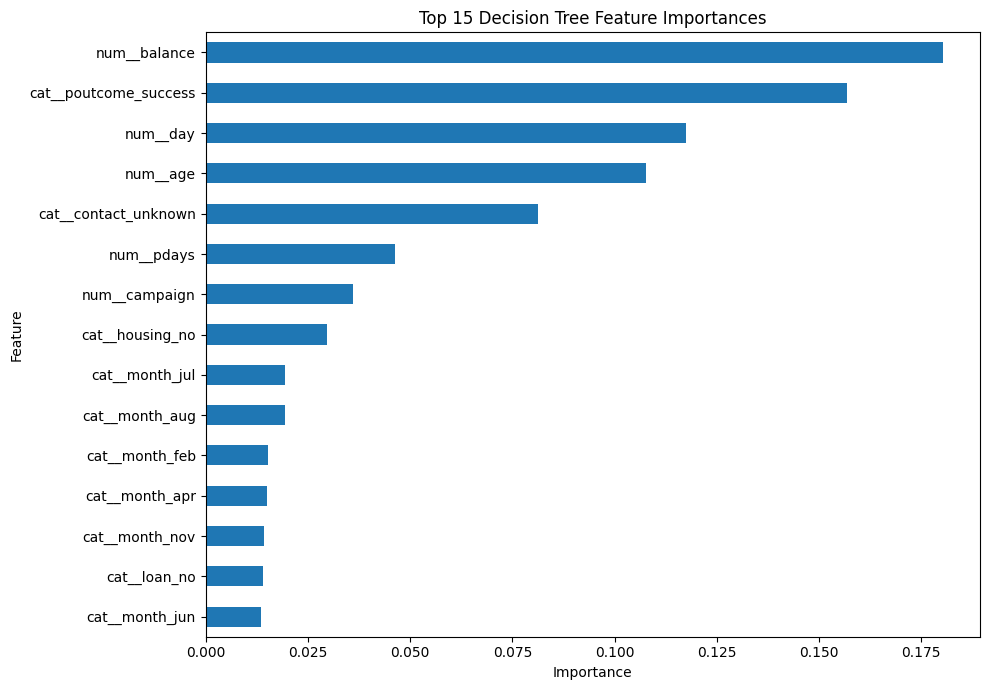

In [45]:
feature_importance_df.head(15).plot(
    x="feature", y="importance", kind="barh", figsize=(10, 7), legend=False
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Decision Tree Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("visuals/feature_importance_impurity.png", dpi=150)
plt.show()

### 16.2 Aggregated Impurity Importance (grouped back to original features)

In [46]:
impurity_df = pd.DataFrame({
    "transformed_feature": feature_names,
    "importance": importances
})

all_features = categorical_features + numerical_features
aggregated_importance = []

for feature in all_features:
    if feature in categorical_features:
        mask = impurity_df["transformed_feature"].str.startswith(f"cat__{feature}_")
    else:
        mask = impurity_df["transformed_feature"] == f"num__{feature}"

    total_importance = impurity_df.loc[mask, "importance"].sum()
    aggregated_importance.append({"feature": feature, "impurity_importance": total_importance})

aggregated_impurity_df = pd.DataFrame(aggregated_importance).sort_values(
    by="impurity_importance", ascending=False
)

aggregated_impurity_df

,feature,impurity_importance
10,balance,0.180325
8,poutcome,0.161664
7,month,0.136414
11,day,0.117471
9,age,0.107596
6,contact,0.084684
13,pdays,0.046266
12,campaign,0.036040
2,education,0.031887
4,housing,0.029797


### 16.3 Permutation Importance (model-agnostic, more robust)

In [47]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_model, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1
)

original_features = X_test.columns.tolist()

permutation_df = pd.DataFrame({
    "feature": original_features,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(by="importance_mean", ascending=False)

permutation_df

,feature,importance_mean,importance_std
10,month,0.028172,0.007815
14,poutcome,0.027821,0.002579
8,contact,0.024992,0.004685
6,housing,0.020428,0.005969
5,balance,0.010900,0.008736
7,loan,0.010283,0.002772
0,age,0.009153,0.004560
3,education,0.004608,0.003299
12,pdays,0.003892,0.003757
2,marital,0.003557,0.003741


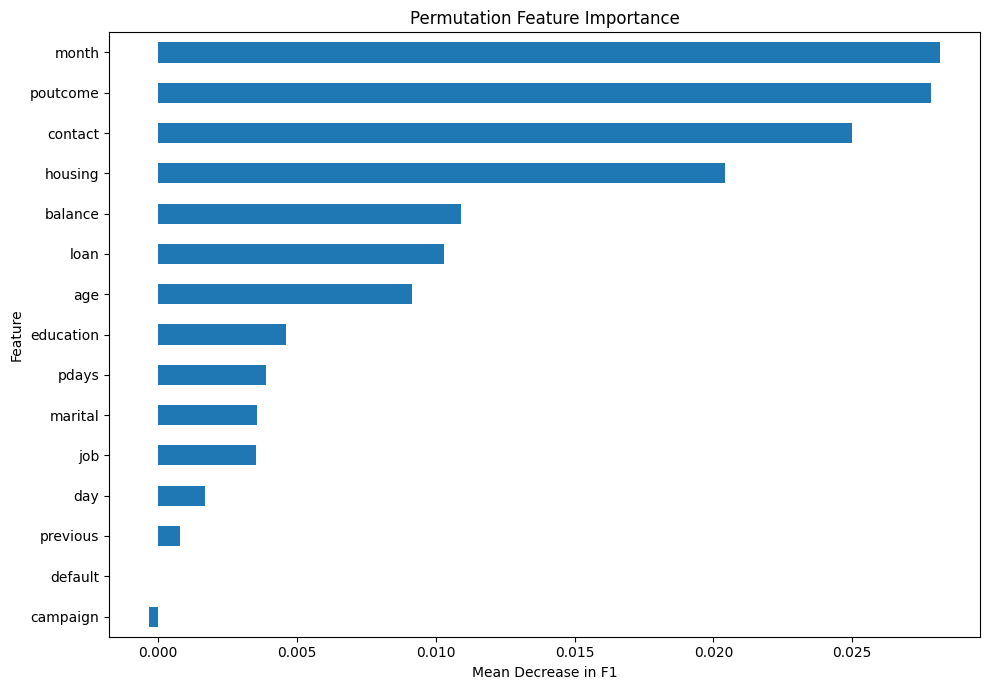

In [48]:
permutation_df.plot(
    x="feature", y="importance_mean", kind="barh", figsize=(10, 7), legend=False
)
plt.xlabel("Mean Decrease in F1")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("visuals/permutation_importance.png", dpi=150)
plt.show()

## 17. Save Final Model

In [49]:
import joblib

model_artifact = {
    "model": best_model,
    "threshold": best_threshold,
    "features": features
}

joblib.dump(model_artifact, "models/bank_marketing_decision_tree.pkl")
print("Model saved successfully!")

Model saved successfully!


In [50]:
artifact = joblib.load("models/bank_marketing_decision_tree.pkl")

loaded_model = artifact["model"]
loaded_threshold = artifact["threshold"]
loaded_features = artifact["features"]

print("Model loaded successfully.")
print("Threshold:", loaded_threshold)
print("Number of features:", len(loaded_features))
print("Features:", loaded_features)

Model loaded successfully.
Threshold: 0.3
Number of features: 15
Features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


## 18. Example: Predicting a New Customer

In [51]:
new_customer = pd.DataFrame([{
    "age": 35,
    "job": "management",
    "marital": "married",
    "education": "tertiary",
    "default": "no",
    "balance": 1500,
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "day": 15,
    "month": "may",
    "campaign": 2,
    "pdays": -1,
    "previous": 0,
    "poutcome": "unknown"
}])

new_customer

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
0,35,management,married,tertiary,no,1500,yes,no,cellular,15,may,2,-1,0,unknown


In [52]:
probability = loaded_model.predict_proba(new_customer)[0, 1]
prediction = "yes" if probability >= loaded_threshold else "no"

print("Deposit probability:", probability)
print("Prediction:", prediction)

Deposit probability: 0.8
Prediction: yes


## 19. Reusable Prediction Function

In [53]:
def predict_customer(customer_data, model, threshold=0.50):

    required_features = [
        "age", "job", "marital", "education", "default",
        "balance", "housing", "loan", "contact", "day",
        "month", "campaign", "pdays", "previous", "poutcome"
    ]

    missing_features = [f for f in required_features if f not in customer_data]

    if missing_features:
        raise ValueError(f"Missing required features: {missing_features}")

    customer_df = pd.DataFrame(
        [[customer_data[feature] for feature in required_features]],
        columns=required_features
    )

    probability = model.predict_proba(customer_df)[0, 1]
    prediction = "yes" if probability >= threshold else "no"

    return {
        "deposit_probability": float(round(probability, 4)),
        "prediction": prediction
    }

In [54]:
customer = {
    "age": 35,
    "job": "management",
    "marital": "married",
    "education": "tertiary",
    "default": "no",
    "balance": 1500,
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "day": 15,
    "month": "may",
    "campaign": 2,
    "pdays": -1,
    "previous": 0,
    "poutcome": "unknown"
}

result = predict_customer(customer, loaded_model, loaded_threshold)
print(result)

{'deposit_probability': 0.8, 'prediction': 'yes'}
